In [224]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import nltk
import re
!pip install emoji
import emoji
nltk.download('punkt')
from nltk.tokenize import word_tokenize,sent_tokenize
from nltk.corpus import stopwords
nltk.download('stopwords')
import string
from textblob import TextBlob
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
nltk.download('punkt_tab')
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [225]:
!unzip Twitter\ Sentiment\ Analysis.zip

Archive:  Twitter Sentiment Analysis.zip
replace twitter_training.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: twitter_training.csv    
replace twitter_validation.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: twitter_validation.csv  


In [226]:
df_train = pd.read_csv('/content/twitter_training.csv')
df_test = pd.read_csv('/content/twitter_validation.csv')

In [227]:
print('Training data:\n',df_train.shape,'\n','Testing data: \n',df_test.shape)

Training data:
 (74681, 4) 
 Testing data: 
 (999, 4)


In [228]:
df_train.head()

,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [229]:
df_test.head()

,3364,Facebook,Irrelevant,"I mentioned on Facebook that I was struggling for motivation to go for a run the other day, which has been translated by Tom’s great auntie as ‘Hayley can’t get out of bed’ and told to his grandma, who now thinks I’m a lazy, terrible person 🤣"
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...


In [230]:
cols = ["id", "entity", "sentiment", "text"]

df_train.columns = cols
df_test.columns = cols

In [231]:
df_train.head()

,id,entity,sentiment,text
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [232]:
df_test.head()

,id,entity,sentiment,text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...


In [233]:
df_train.drop(['id','entity'],axis=1,inplace=True)
df_test.drop(['id','entity'],axis=1,inplace=True)

In [234]:
df_train

,sentiment,text
0,Positive,I am coming to the borders and I will kill you...
1,Positive,im getting on borderlands and i will kill you ...
2,Positive,im coming on borderlands and i will murder you...
3,Positive,im getting on borderlands 2 and i will murder ...
4,Positive,im getting into borderlands and i can murder y...
...,...,...
74676,Positive,Just realized that the Windows partition of my...
74677,Positive,Just realized that my Mac window partition is ...
74678,Positive,Just realized the windows partition of my Mac ...
74679,Positive,Just realized between the windows partition of...


In [235]:
df_test

,sentiment,text
0,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,Negative,@Microsoft Why do I pay for WORD when it funct...
2,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,Neutral,Now the President is slapping Americans in the...
4,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...
...,...,...
994,Irrelevant,⭐️ Toronto is the arts and culture capital of ...
995,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
996,Positive,Today sucked so it’s time to drink wine n play...
997,Positive,Bought a fraction of Microsoft today. Small wins.


In [236]:
df_train.isnull().sum()

,0
sentiment,0
text,686


In [237]:
df_test.isnull().sum()

,0
sentiment,0
text,0


In [238]:
df_train.dropna(subset=['text'],inplace=True)
df_train.reset_index(drop=True,inplace=True)

In [239]:
df_train.isnull().sum()

,0
sentiment,0
text,0


In [240]:
print('Training data:\n',df_train.shape,'\n','Testing data: \n',df_test.shape)

Training data:
 (73995, 2) 
 Testing data: 
 (999, 2)


In [241]:
df_train['text']=df_train['text'].apply(lambda x:x.lower())
df_test['text']=df_test['text'].apply(lambda x:x.lower())

In [242]:
def remove_html_tags(text):
    pattern = re.compile('<.*?>')
    return pattern.sub(r'', text)

In [243]:
def remove_url(text):
    pattern = re.compile(r'https?://\S+|www\.\S+')
    return pattern.sub(r'', text)

In [244]:
exclude=string.punctuation
def remove_punc(text):
    return text.translate(str.maketrans('', '', exclude))

In [245]:
!pip install contractions
import contractions

In [246]:
df_train["text"] = df_train["text"].apply(lambda x: emoji.demojize(x))
df_train['text'] = df_train["text"].apply(lambda x: remove_html_tags(x))
df_train['text'] = df_train["text"].apply(lambda x: remove_url(x))
df_train['text'] = df_train["text"].apply(lambda x: remove_punc(x))
df_train["text"] = df_train["text"].apply(contractions.fix)

In [247]:
df_test["text"] = df_test["text"].apply(lambda x: emoji.demojize(x))
df_test['text'] = df_test["text"].apply(lambda x: remove_html_tags(x))
df_test['text'] = df_test["text"].apply(lambda x: remove_url(x))
df_test['text'] = df_test["text"].apply(lambda x: remove_punc(x))
df_test["text"] = df_test["text"].apply(contractions.fix)

In [248]:
df_train.head()

,sentiment,text
0,Positive,i am coming to the borders and i will kill you...
1,Positive,i am getting on borderlands and i will kill yo...
2,Positive,i am coming on borderlands and i will murder y...
3,Positive,i am getting on borderlands 2 and i will murde...
4,Positive,i am getting into borderlands and i can murder...


In [249]:
df_test.head()

,sentiment,text
0,Neutral,bbc news amazon boss jeff bezos rejects claim...
1,Negative,microsoft why do i pay for word when it functi...
2,Negative,csgo matchmaking is so full of closet hacking ...
3,Neutral,now the president is slapping americans in the...
4,Negative,hi eahelp i have had madeleine mccann in my ce...


In [250]:
stop_words=set(stopwords.words('english'))

def remove_stopwords(text):
  word=text.split()
  filtered=[x for x in word if x.lower() not in stop_words]
  return ' '.join(filtered)

In [251]:
df_train['text']=df_train['text'].apply(remove_stopwords)
df_test['text']=df_test['text'].apply(remove_stopwords)

In [252]:
#In this project meaning of words matters, so we would use Lemmatizier and not Stemmer
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
  return " ".join(lemmatizer.lemmatize(x) for x in text.split())

In [253]:
df_train['text']=df_train['text'].apply(lemmatize_text)
df_test['text']=df_test['text'].apply(lemmatize_text)

In [254]:
df_train.head()

,sentiment,text
0,Positive,coming border kill
1,Positive,getting borderland kill
2,Positive,coming borderland murder
3,Positive,getting borderland 2 murder
4,Positive,getting borderland murder


In [255]:
df_test.head()

,sentiment,text
0,Neutral,bbc news amazon bos jeff bezos reject claim co...
1,Negative,microsoft pay word function poorly samsungus c...
2,Negative,csgo matchmaking full closet hacking truly awf...
3,Neutral,president slapping american face really commit...
4,Negative,hi eahelp madeleine mccann cellar past 13 year...


In [256]:
X_train=df_train['text']
y_train=df_train['sentiment']
X_test=df_test['text']
y_test=df_test['sentiment']

In [257]:
print(df_train["text"].duplicated().sum(), "repeated tweets in train")
print(df_test["text"].isin(df_train["text"]).sum(), "test tweets also in train")

11951 repeated tweets in train
604 test tweets also in train


In [258]:
df_train = df_train.drop_duplicates(subset=["text"])

In [259]:
print(df_train["text"].duplicated().sum(), "repeated tweets in train")
print(df_test["text"].isin(df_train["text"]).sum(), "test tweets also in train")

0 repeated tweets in train
604 test tweets also in train


In [260]:
df_train = df_train[~df_train["text"].isin(df_test["text"])]
# Fix the row numbers after deleting
df_train = df_train.reset_index(drop=True)

In [261]:
print(df_train["text"].duplicated().sum(), "repeated tweets in train")
print(df_test["text"].isin(df_train["text"]).sum(), "test tweets also in train")

0 repeated tweets in train
0 test tweets also in train


In [262]:
print(df_train["sentiment"].value_counts())
print(df_test["sentiment"].value_counts())

sentiment
Negative      18617
Positive      16378
Neutral       15566
Irrelevant    10882
Name: count, dtype: int64
sentiment
Neutral       285
Positive      277
Negative      266
Irrelevant    171
Name: count, dtype: int64


In [263]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

# Models and the settings to try
# C = 0.1 (relaxed): the student learns the main ideas only. They don't memorize every small detail.
# They make a few mistakes on practice questions, but they handle new questions well.
# C = 10 (strict): the student memorizes every practice question. They get almost 100% on practice,
# but they may struggle on new questions, because they memorized instead of understanding.
# alpha (Naive Bayes): adds a small number to every word count, so no word gets a zero chance.
models = [
    ("Logistic Regression", LogisticRegression(max_iter=1000), {"model__C": [1, 5, 10]}),
    ("Linear SVC", LinearSVC(), {"model__C": [1, 5, 10]}),
    ("Naive Bayes", MultinomialNB(), {"model__alpha": [0.1, 0.5, 1.0]}),
]

# Empty dictionary to save each trained grid.
# Without this, "grid" is replaced in every loop, and only the last model (Naive Bayes) is kept.
grids = {}
scores = {}

for name, model, params in models:
    # Pipeline = TF-IDF (turns text into numbers) + model
    # ngram_range=(1, 2) also looks at word pairs like "not good"
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("model", model)
    ])

    # cv=3: split the train data into 3 parts to test each setting
    grid = GridSearchCV(pipe, params, cv=3, scoring='accuracy')
    grid.fit(df_train["text"], df_train["sentiment"])

    score = grid.score(df_test["text"], df_test["sentiment"])

    # Save this model's grid and score, so they are not lost in the next loop
    grids[name] = grid
    scores[name] = score

    print(name)
    print("Best settings:", grid.best_params_)
    print("Test score:", score)
    print()

# Find the name of the model with the highest test score
best_name = max(scores, key=scores.get)
best_model = grids[best_name].best_estimator_
print("Best model:", best_name)

Logistic Regression
Best settings: {'model__C': 1}
Test score: 0.944944944944945

Linear SVC
Best settings: {'model__C': 1}
Test score: 0.978978978978979

Naive Bayes
Best settings: {'model__alpha': 1.0}
Test score: 0.918918918918919

Best model: Linear SVC


In [264]:
# Check the best model in detail
pred = best_model.predict(df_test["text"])
print(classification_report(df_test["sentiment"], pred))

              precision    recall  f1-score   support

  Irrelevant       0.99      0.98      0.99       171
    Negative       0.98      0.98      0.98       266
     Neutral       0.99      0.97      0.98       285
    Positive       0.96      0.98      0.97       277

    accuracy                           0.98       999
   macro avg       0.98      0.98      0.98       999
weighted avg       0.98      0.98      0.98       999



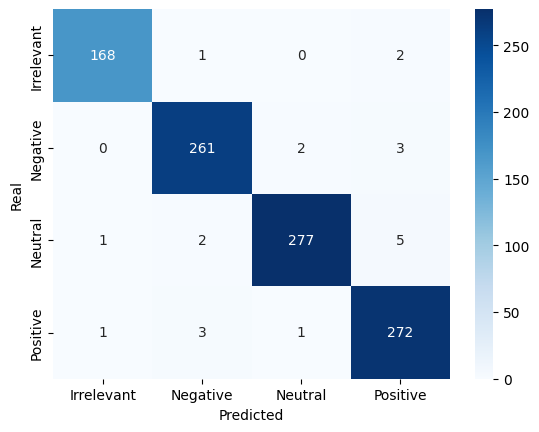

In [265]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = best_model.classes_   # class names in the right order

sns.heatmap(confusion_matrix(df_test["sentiment"], pred),
            annot=True,        # show the numbers in each square
            fmt="d",           # show whole numbers, not 1.6e+02
            xticklabels=labels,
            yticklabels=labels,
            cmap="Blues")      # easier colors

plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

In [266]:
import pickle
# best_model is a full pipeline (TF-IDF + model), so it can take raw text directly
pickle.dump(best_model, open("sentiment.pkl", "wb"))